---
title: "The most important discrete distributions: binomial, Poisson, geometric"
short_title: "The most important discrete distributions"
description: "Uniform, categorical, Bernoulli, binomial, Poisson and geometric distributions in SciPy, with expected value, variance, entropy, and which p fits the data."
---

We now have everything we need for an overview of the most important
discrete distributions: the pmf from the chapter
[Random variables and distributions](random-variables-distributions.md), expected value, variance and
entropy from the chapter [Expected value and variance](expectation-variance.md), and from the
chapter [Numpy](numpy.ipynb) the machinery for actually computing with them.

We present every distribution in the same format – parameters, pmf, expected value, variance,
entropy, example applications and the name in `scipy.stats` – just as we will later do for the
[continuous distributions](important-continuous-distributions.ipynb).


## Convention: discrete probability spaces

In this chapter $\Omega$ is always *at most countable*, and usually even finite.
Then the power set $\mathcal{P}(\Omega)$ is a σ-algebra, so every subset of $\Omega$ is an
event, and the probability measure $P$ is completely determined by the values

$$
p(\omega) := P(\{\omega\})
$$

on the individual outcomes – because every event $A \subseteq \Omega$ is the (at most countable)
disjoint union of its elements, so that $P(A) = \sum_{\omega \in A} p(\omega)$.
This function $p$ is the *probability mass function* (pmf); *discrete density* is another
name in common use. Everything we want to know about a discrete distribution can be read off it:

$$
\mathbb{E}(X) = \sum_{x} x\,p_X(x), \qquad
\mathbb{V}(X) = \mathbb{E}(X^2) - {\left(\mathbb{E}X\right)}^2, \qquad
H(X) = -\sum_{x} p_X(x)\log_2 p_X(x).
$$

```{admonition} Remark
:class: note
Some sources call the pmf the *distribution function* in the discrete case. We avoid that
name: in the chapter [Continuous distributions](continuous-distributions.md) it belongs to
the *cumulative* distribution function $F(x) = P(X \leq x)$.
```


## Discrete distributions in SciPy

`scipy.stats` provides objects for discrete distributions just as it does for continuous ones.
The main difference: where a continuous distribution has a density `pdf`, a discrete
distribution has a pmf, and the method is accordingly called `pmf`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st


def plotXdiscrete(k, X, name, params):
    description = ", ".join(f"{value}" for value in params)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    # First the probability mass function:
    axs[0].stem(k, X.pmf(k), basefmt=" ")
    axs[0].set_xlabel("$k$")
    axs[0].set_ylabel("$p(k) = P(X = k)$")
    axs[0].set_title(f"pmf of the {name} with {description}")
    # Then the cumulative distribution function:
    axs[1].step(k, X.cdf(k), where="post")
    axs[1].set_xlabel("$k$")
    axs[1].set_ylabel("$F(k) = P(X \\leq k)$")
    axs[1].set_title(f"cdf of the {name}")
    # tight_layout keeps the two sets of axis labels from overlapping:
    plt.tight_layout()
    plt.show()


The methods we need over and over again are the same for every distribution.
If `X` is a discrete random variable from `scipy.stats`, then:

| wanted | call |
|---|---|
| $P(X = k)$ | `X.pmf(k)` |
| $P(X \leq k)$ | `X.cdf(k)` |
| $P(X > k)$ | `X.sf(k)`, equivalent to `1 - X.cdf(k)` |
| $P(X \geq k)$ | `X.sf(k-1)` |
| $P(X < k)$ | `X.cdf(k-1)` |
| a sample of size $n$ | `X.rvs(size=n)` |
| $\mathbb{E}(X)$, $\mathbb{V}(X)$, $\sigma(X)$ | `X.mean()`, `X.var()`, `X.std()` |

The `sf` stands for *survival function*.

```{admonition} Caution
:class: warning
For discrete distributions the difference between $\leq$ and $<$ is not merely cosmetic, because
individual values carry strictly positive probability. "At most $k$" is `X.cdf(k)`,
"fewer than $k$" is `X.cdf(k-1)`, "more than $k$" is `X.sf(k)` and "at least $k$" is
`X.sf(k-1)`. This is by far the most common source of error when computing with these distributions.
```


In [2]:
X = st.binom(10, 0.3)
print("P(X = 3)   =", X.pmf(3))
print("P(X <= 3)  =", X.cdf(3))
print("P(X > 3)   =", X.sf(3), "= 1 - P(X <= 3) =", 1 - X.cdf(3))
print("P(X >= 3)  =", X.sf(2))
assert np.isclose(X.cdf(3) + X.sf(3), 1.0)


P(X = 3)   = 0.2668279319999998
P(X <= 3)  = 0.6496107184000002
P(X > 3)   = 0.3503892815999998 = 1 - P(X <= 3) = 0.3503892815999998
P(X >= 3)  = 0.6172172136000003


## Discrete uniform distribution

* Parameter $n$, notation $\operatorname{Uni}\{1,\dots,n\}$
* pmf $p(k) = \dfrac{1}{n}$ for $k \in \{1,\dots,n\}$
* Expected value $\dfrac{n+1}{2}$
* Variance $\dfrac{n^2-1}{12}$
* Entropy $\log_2 n$ – the maximum among all distributions on a set with $n$ elements
  (see [Expected value and variance](expectation-variance.md), section Entropy)
* Example applications:
  * The fair die: $n=6$, so $\mathbb{E}(X) = 3.5$ and $\mathbb{V}(X) = \frac{35}{12} \approx 2.92$.
  * An idealised random number generator that returns integers in a fixed range.
* In `scipy.stats`: `st.randint(1, n+1)` – careful: as with `range`, the upper bound is **exclusive**.

We already know the expected value. For the variance we use
$\mathbb{V}(X) = \mathbb{E}(X^2) - (\mathbb{E}X)^2$. With the summation formula
$\sum_{i=1}^n i^2 = \frac{n(n+1)(2n+1)}{6}$ we get

$$
\mathbb{E}(X^2) = \frac{1}{n}\sum_{i=1}^n i^2 = \frac{(n+1)(2n+1)}{6},
$$

and therefore

$$
\mathbb{V}(X) = \frac{(n+1)(2n+1)}{6} - \frac{(n+1)^2}{4}
              = \frac{(n+1)\left( 2(2n+1) - 3(n+1) \right)}{12}
              = \frac{(n+1)(n-1)}{12}
              = \frac{n^2-1}{12}.
$$


E(X) = 3.5  expected: 3.5
V(X) = 2.9166666666666665  expected: 2.9166666666666665


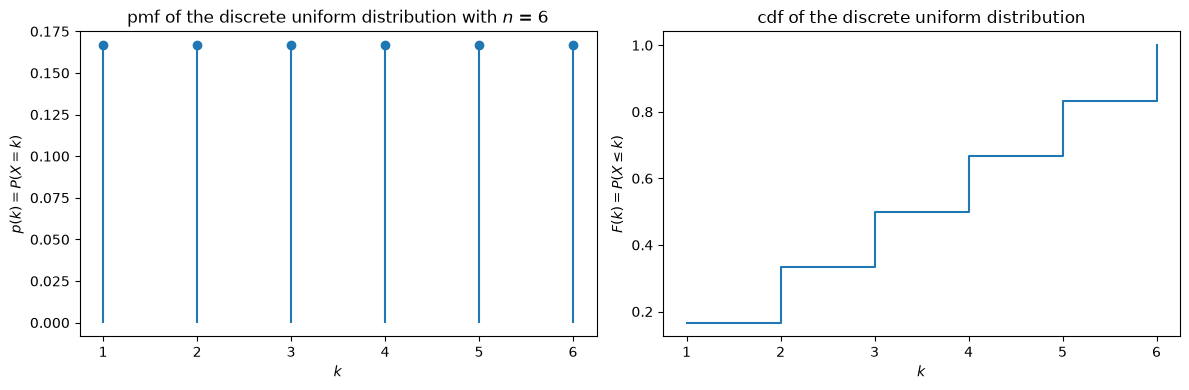

In [3]:
n = 6
X = st.randint(1, n + 1)   # upper bound exclusive, so 1 to 6
print("E(X) =", X.mean(), " expected:", (n + 1) / 2)
print("V(X) =", X.var(),  " expected:", (n**2 - 1) / 12)

plotXdiscrete(np.arange(1, n + 1), X, "discrete uniform distribution", (f"$n$ = {n}",))


## Categorical distribution

* Parameter a probability vector $p = (p_1,\dots,p_n) \in \Delta_n$, that is $p_i \geq 0$ and $\sum_i p_i = 1$
* pmf $p(\omega_i) = p_i$ on a set $\Omega = \{\omega_1,\dots,\omega_n\}$ with $n$ elements
* Expected value (if we identify $\omega_i$ with the number $i$) $\sum_{i=1}^n i\,p_i$ – which
  in general does not simplify any further
* Variance $\sum_{i=1}^n i^2 p_i - \left(\sum_{i=1}^n i\,p_i\right)^2$
* Entropy $-\sum_i p_i \log_2 p_i$
* Example applications:
  * An urn with $m$ balls in $n$ colours, $n_i$ of them of colour $i$; drawing **with** replacement
    gives $p_i = \frac{n_i}{m}$.
  * Any survey with a fixed list of mutually exclusive answers.
* In `scipy.stats`: no object of its own, but `st.rv_discrete(values=(values, p))` builds one;
  if all you want is to draw samples, `rng.choice(values, p=p)` from the chapter [Numpy](numpy.ipynb) is enough.

The parameter space is exactly the simplex $\Delta_n$ we met in the chapter
[Random variables and distributions](random-variables-distributions.md): the uniform
distribution sits at its centre, the Dirac distributions at its vertices. The categorical
distribution is therefore the most general distribution on a finite set – every distribution
that follows in this chapter is either a special case of it or built from it. The four jumper colours
from that chapter are a categorical distribution too, with $n=4$.

```{admonition} Remark
:class: note
In machine learning $\Delta_n$ shows up as an *output space*: when a classification algorithm is meant
not merely to name a class but to express how uncertain it is, it returns a point in $\Delta_n$ –
a categorical distribution over the classes.
```


E(X) = 2.4  recomputed: 2.4
V(X) = 0.6400000000000006
H(X) = 1.6854752972273344 bits
for comparison, uniform distribution on 4 values: 2.0 bits


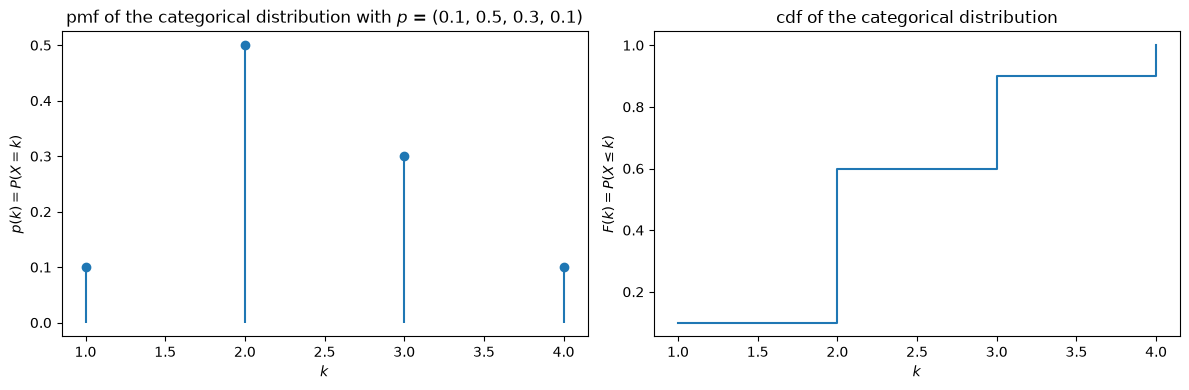

In [4]:
values = np.arange(1, 5)
p = np.array([0.1, 0.5, 0.3, 0.1])
X = st.rv_discrete(values=(values, p))

print("E(X) =", X.mean(), " recomputed:", np.sum(values * p))
print("V(X) =", X.var())
print("H(X) =", X.entropy() / np.log(2), "bits")   # scipy computes in nats
print("for comparison, uniform distribution on 4 values:", np.log2(4), "bits")

plotXdiscrete(values, X, "categorical distribution", (f"$p$ = {tuple(p.tolist())}",))


## Bernoulli distribution

* Parameter $p \in [0,1]$, notation $\operatorname{Ber}(p)$
* pmf $p(1) = p$ and $p(0) = 1-p$ on $\Omega = \{0,1\}$
* Expected value $p$
* Variance $p(1-p)$
* Entropy $h(p) := -p\log_2 p - (1-p)\log_2(1-p)$, the *binary entropy function*
* Example applications:
  * A single coin toss, unfair coins included.
  * Any yes/no feature: a component is defective or it is not, an email is spam or it is not.
* In `scipy.stats`: `st.bernoulli(p)`

The Bernoulli distribution is the special case $n=2$ of the categorical distribution, and the simplest
nontrivial case there is – it has **one** parameter. Expected value and variance are quick to
compute: $\mathbb{E}(X) = 0\cdot(1-p) + 1\cdot p = p$, and since $X^2 = X$ (because $0^2=0$ and $1^2=1$),
we also have $\mathbb{E}(X^2) = p$ and therefore

$$
\mathbb{V}(X) = \mathbb{E}(X^2) - {\left(\mathbb{E}X\right)}^2 = p - p^2 = p(1-p).
$$

The variance is maximal at $p = \frac12$ and vanishes for $p \in \{0,1\}$ – there the outcome
is no longer random at all.

In the chapter [Random variables and distributions](random-variables-distributions.md) we already
estimated a value $\hat\pi$ from data without giving it a name: it was the parameter of a
Bernoulli distribution.


### The binary entropy function

The entropy of a Bernoulli distribution, as a function of $p$, deserves a look of its own.
Let us differentiate it. With $\log_2 x = \frac{\ln x}{\ln 2}$ we have

$$
\frac{d}{dp}\left( -p\log_2 p \right) = -\log_2 p - \frac{1}{\ln 2},
\qquad
\frac{d}{dp}\left( -(1-p)\log_2(1-p) \right) = \log_2(1-p) + \frac{1}{\ln 2},
$$

so the two constants cancel and what remains is

$$
h'(p) = \log_2(1-p) - \log_2 p = -\log_2\frac{p}{1-p}.
$$

The only zero is at $p = 1-p$, that is, at $p = \frac12$: the fair coin toss has the maximal
entropy, namely $h(\frac12) = 1$ bit. That fits: the uniform distribution is the maximum entropy distribution.

```{admonition} Looking ahead
:class: tip
The expression $\log_2\frac{p}{1-p}$ we have run into here has a name of its own: the fraction
$\frac{p}{1-p}$ is called the *odds*, and its logarithm the *logit*. So the derivative
of the binary entropy is exactly the negative of the logit. The inverse of the logit is the
logistic sigmoid function, the building block from which *logistic regression* – and
with it the single neuron of a neural network – is built. Anyone taking
*Introduction to Deep Learning* after this course will meet this curve again straight away.
```


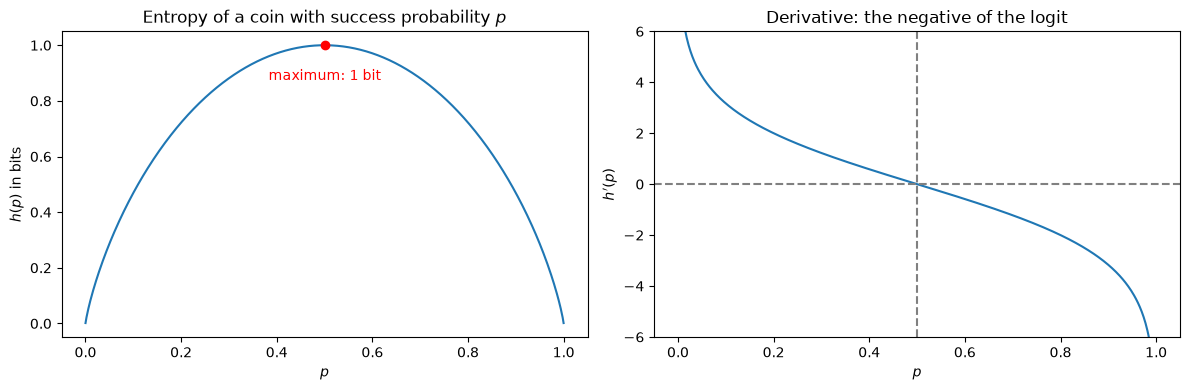

E(X) = 0.3  V(X) = 0.21  H(X) = 0.8812908992306927 bits


In [5]:
p = np.linspace(1e-4, 1 - 1e-4, 500)
h = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
h_prime = -np.log2(p / (1 - p))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(p, h)
axs[0].plot(0.5, 1.0, "o", color="red")
axs[0].annotate("maximum: 1 bit", (0.5, 1.0), textcoords="offset points",
                xytext=(0, -25), ha="center", color="red")
axs[0].set_xlabel("$p$")
axs[0].set_ylabel("$h(p)$ in bits")
axs[0].set_title("Entropy of a coin with success probability $p$")

axs[1].plot(p, h_prime)
axs[1].axhline(0, linestyle="--", color="gray")
axs[1].axvline(0.5, linestyle="--", color="gray")
axs[1].set_ylim(-6, 6)
axs[1].set_xlabel("$p$")
axs[1].set_ylabel("$h'(p)$")
axs[1].set_title("Derivative: the negative of the logit")

plt.tight_layout()
plt.show()

X = st.bernoulli(0.3)
print("E(X) =", X.mean(), " V(X) =", X.var(), " H(X) =", X.entropy() / np.log(2), "bits")


## Binomial distribution

* Parameters $n \in \mathbb{N}$ and $p \in [0,1]$, notation $\operatorname{Bin}(n,p)$
* pmf $p(k) = \dbinom{n}{k}p^k(1-p)^{n-k}$ for $k \in \{0,1,\dots,n\}$
* Expected value $np$
* Variance $np(1-p)$
* Entropy: no convenient closed expression; it is smaller than $\log_2(n+1)$, since the maximum
  would be the uniform distribution on $\{0,\dots,n\}$
* Example applications:
  * Tossing the same coin $n$ times and counting the heads.
  * Drawing a sample of $n$ components and counting the defective ones.
  * An urn with two colours, $N$ balls of which $n_1$ are red, $p = \frac{n_1}{N}$, drawing $n$ times **with** replacement.
* In `scipy.stats`: `st.binom(n, p)`

The binomial distribution arises from the Bernoulli distribution by repetition. If
$X_1,\dots,X_n$ are **independent** random variables with $X_i \sim \operatorname{Ber}(p)$, then

$$
X := \sum_{i=1}^n X_i
$$

counts the number of successes, and $X \sim \operatorname{Bin}(n,p)$. So it has **two** parameters.

Why the pmf looks the way it does: by independence, any one fixed pattern of $k$ successes and $n-k$ failures – say
$1,1,0,1,0,\dots$ – has probability $p^k(1-p)^{n-k}$, whichever positions the successes
occupy. And there are exactly $\binom{n}{k}$ such patterns, one for each subset of
$\{1,\dots,n\}$ with $k$ elements. Summing over them gives the formula.

Expected value and variance now come for free. The expected value follows from linearity:

$$
\mathbb{E}(X) = \sum_{i=1}^n \mathbb{E}(X_i) = n\,p.
$$

For the variance we need the independence – this is exactly the rule of calculation from the section
[Rules of calculation for the variance](expectation-variance.md):

$$
\mathbb{V}(X) = \sum_{i=1}^n \mathbb{V}(X_i) = n\,p(1-p).
$$

Without independence this would be false. Here you can see clearly what that rule is good for.


E(X) = 3.0  expected: 3.0
V(X) = 2.1  expected: 2.0999999999999996


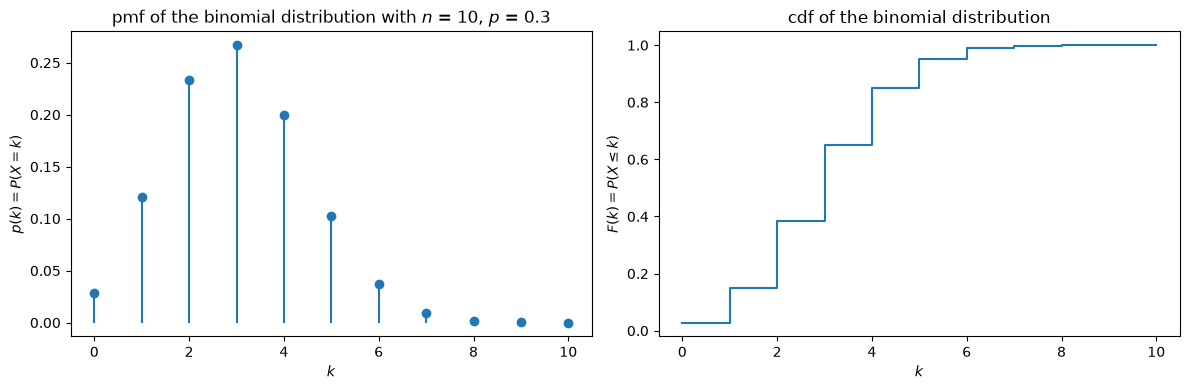

In [6]:
n, p = 10, 0.3
X = st.binom(n, p)
print("E(X) =", X.mean(), " expected:", n * p)
print("V(X) =", X.var(),  " expected:", n * p * (1 - p))

plotXdiscrete(np.arange(0, n + 1), X, "binomial distribution", (f"$n$ = {n}", f"$p$ = {p}"))


### Which p fits the data best?

So far we have treated $p$ as given and asked for the probability of $k$ successes.
Now we turn the question around: we have found $k = 3$ defective components in a sample of $n = 10$
and want to know which $p$ fits this observation.

For **every** $p$ the pmf gives us a probability for exactly this observation:

$$
P(X = 3) = \binom{10}{3}p^3(1-p)^{7}.
$$

Let us compare two candidates, $p = 0.2$ and $p = 0.5$. The binomial coefficient is the same in both
cases and cancels, so it is enough to compare $p^3(1-p)^7$:

$$
0.2^3 \cdot 0.8^7 = 0.008 \cdot 0.2097\ldots \approx 0.00168,
\qquad
0.5^3 \cdot 0.5^7 = 0.5^{10} \approx 0.00098.
$$

So our observation is about $1.7$ times as likely under $p = 0.2$ as under $p = 0.5$.
In this sense $p = 0.2$ fits better.

The natural next question is which $p$ fits best of all. We are looking for the maximum of
$p \mapsto p^k(1-p)^{n-k}$, so we differentiate:

$$
\frac{d}{dp}\left( p^k(1-p)^{n-k} \right)
 = k\,p^{k-1}(1-p)^{n-k} - (n-k)\,p^k(1-p)^{n-k-1}
 = p^{k-1}(1-p)^{n-k-1}\Big( k(1-p) - (n-k)p \Big).
$$

For $0 < p < 1$ the leading factor is nonzero, so what remains is the condition $k(1-p) = (n-k)p$.
Solving it: $k - kp = np - kp$, so $k = np$ and therefore

$$
p = \frac{k}{n}.
$$

For our observation that is $p = \frac{3}{10} = 0.3$ – simply the proportion of successes in the
sample. That is exactly what you would have guessed without any calculation; what is remarkable is that
here it drops out of a calculation, from a clearly stated criterion:
choose the parameter that makes the observation you actually made as likely as possible.


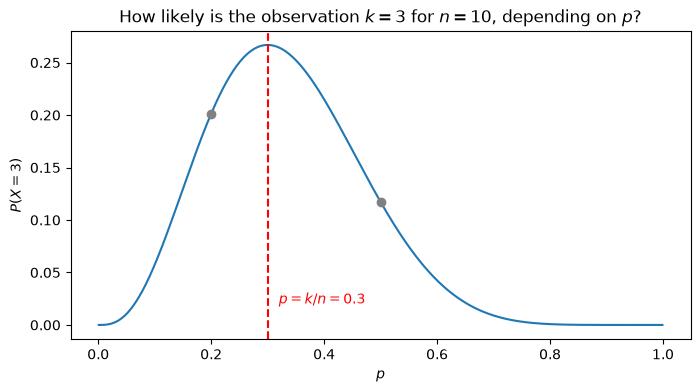

P(X=3) at p=0.2: 0.20132659199999992
P(X=3) at p=0.5: 0.1171875
P(X=3) at p=0.3: 0.2668279319999998   <- the maximum


In [7]:
k, n = 3, 10
p = np.linspace(0.001, 0.999, 500)
probability = st.binom(n, p).pmf(k)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(p, probability)
ax.axvline(k / n, linestyle="--", color="red")
ax.annotate(f"$p = k/n = {k/n}$", (k / n, 0.02), color="red",
            textcoords="offset points", xytext=(8, 0))
for candidate in (0.2, 0.5):
    ax.plot(candidate, st.binom(n, candidate).pmf(k), "o", color="gray")
ax.set_xlabel("$p$")
ax.set_ylabel(f"$P(X = {k})$")
ax.set_title(f"How likely is the observation $k={k}$ for $n={n}$, depending on $p$?")
plt.show()

print("P(X=3) at p=0.2:", st.binom(n, 0.2).pmf(k))
print("P(X=3) at p=0.5:", st.binom(n, 0.5).pmf(k))
print("P(X=3) at p=0.3:", st.binom(n, 0.3).pmf(k), "  <- the maximum")


This procedure – choosing the parameter that makes the observation most likely –
is called *maximum likelihood estimation*. The chapter [Statistical models](statistical-models.md)
treats it in general and for other distributions.


## Digression: the Poisson binomial distribution

```{admonition} Note
:class: note
This digression is here mainly to motivate the Poisson distribution in the next section; it can
be skipped on a first reading.
```

* Parameters $p_1,\dots,p_n \in [0,1]$, one probability per trial
* pmf $p(k) = \displaystyle\sum_{A \in F_k} \prod_{i \in A} p_i \prod_{i \notin A} (1-p_i)$,
  where $F_k$ is the set of subsets of $\{1,\dots,n\}$ with $k$ elements
* Expected value $\sum_{i=1}^n p_i$
* Variance $\sum_{i=1}^n p_i(1-p_i)$
* Example application: $n$ components from different batches, each with its own
  failure probability – how many of them fail?
* In `scipy.stats`: no object of its own; the pmf is easy enough to compute yourself.

We are no longer tossing the same coin $n$ times but $n$ different coins, each with its
own success probability $p_i$. The $X_i \sim \operatorname{Ber}(p_i)$ are still
independent, just no longer identically distributed. Expected value and variance therefore follow exactly
as for the binomial distribution, from linearity and from the variance rule for independent summands;
when all the $p_i$ are equal, as for the binomial distribution, we get $np$ and $np(1-p)$ back.

The pmf itself is unwieldy – the sum runs over $\binom{n}{k}$ subsets. In practice it is computed
iteratively: start with "no coins, no successes, with probability 1" and work the coins
in one at a time.

The interesting case is many small $p_i$. If we set every $p_i = \frac{\lambda}{n}$ and let
$n$ grow, the expected value stays fixed at $\lambda$ while each individual trial becomes ever
less likely. This is the passage to the Poisson distribution:

```{admonition} Theorem
Let $\lambda > 0$ and let $(p_n)_n$ be a sequence in $[0,1]$ with $n\,p_n \to \lambda$ as $n \to \infty$.
Then for every fixed $k \in \mathbb{N}_0$

$$
\lim_{n \to \infty} \binom{n}{k} p_n^k (1-p_n)^{n-k} = e^{-\lambda}\frac{\lambda^k}{k!}.
$$

**Without proof**
```


sum of the pmf = 1.0
E(X) = 1.9500000000000004  expected: 1.95
V(X) = 0.7174999999999998  expected: 0.7174999999999999


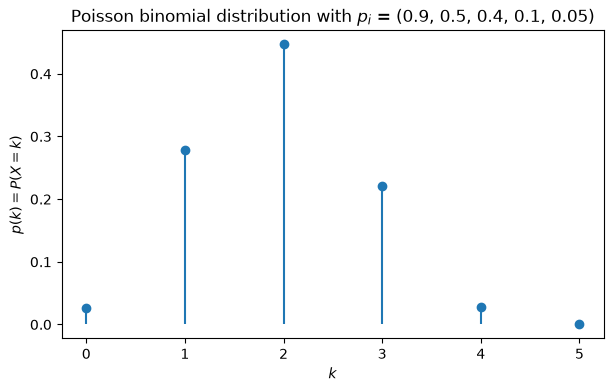

In [8]:
def poisson_binomial_pmf(ps):
    """pmf of a Poisson binomial distribution, built up iteratively.

    We start with "no coins, no successes" and work the coins in one at a time:
    distribution[k] is the probability of k successes among the coins considered so far.
    """
    distribution = np.array([1.0])
    for p in ps:
        without_success = np.append(distribution * (1 - p), 0.0)
        with_success = np.append(0.0, distribution * p)
        distribution = without_success + with_success
    return distribution


ps = np.array([0.9, 0.5, 0.4, 0.1, 0.05])
pmf = poisson_binomial_pmf(ps)
k = np.arange(len(pmf))

print("sum of the pmf =", pmf.sum())
print("E(X) =", np.sum(k * pmf), " expected:", ps.sum())
print("V(X) =", np.sum(k**2 * pmf) - np.sum(k * pmf) ** 2, " expected:", np.sum(ps * (1 - ps)))

fig, ax = plt.subplots(figsize=(7, 4))
ax.stem(k, pmf, basefmt=" ")
ax.set_xlabel("$k$")
ax.set_ylabel("$p(k) = P(X = k)$")
ax.set_title(f"Poisson binomial distribution with $p_i$ = {tuple(ps.tolist())}")
plt.show()


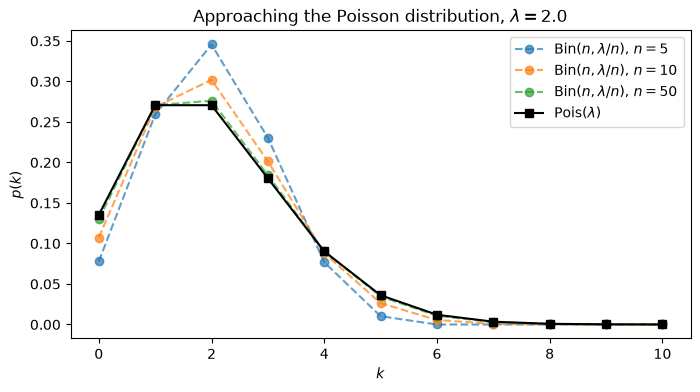

In [9]:
# The passage to the limit: all p_i equal to lambda/n, n grows.
lam = 2.0
k = np.arange(0, 11)

fig, ax = plt.subplots(figsize=(8, 4))
for n in (5, 10, 50):
    ax.plot(k, st.binom(n, lam / n).pmf(k), "o--", alpha=0.7, label=f"$\\operatorname{{Bin}}(n, \\lambda/n)$, $n={n}$")
ax.plot(k, st.poisson(lam).pmf(k), "s-", color="black", label="$\\operatorname{Pois}(\\lambda)$")
ax.set_xlabel("$k$")
ax.set_ylabel("$p(k)$")
ax.set_title(f"Approaching the Poisson distribution, $\\lambda = {lam}$")
ax.legend()
plt.show()


## Poisson distribution

* Parameter $\lambda > 0$, notation $\operatorname{Pois}(\lambda)$
* pmf $p(k) = e^{-\lambda}\dfrac{\lambda^k}{k!}$ for $k \in \mathbb{N}_0$
* Expected value $\lambda$
* Variance $\lambda$
* Example applications:
  * How many requests reach the server in one second?
  * How many typos are there on one page?
  * How many atomic nuclei in a specimen decay in one minute?
* In `scipy.stats`: `st.poisson(mu=λ)`

The guiding question: how many events occur in a fixed period of time, if they occur independently
of one another and at a constant mean rate? In contrast to every distribution in this chapter
so far, this one does not have finite support – in principle there could be arbitrarily many events,
even if large numbers become very unlikely.

That the pmf sums to $1$ follows from the exponential series
$\sum_{k \geq 0} \frac{\lambda^k}{k!} = e^{\lambda}$:

$$
\sum_{k=0}^\infty e^{-\lambda}\frac{\lambda^k}{k!} = e^{-\lambda}e^{\lambda} = 1.
$$

The expected value follows with an index shift – the summand for $k=0$ is $0$ and drops out:

$$
\mathbb{E}(X) = \sum_{k=1}^\infty k\,e^{-\lambda}\frac{\lambda^k}{k!}
              = \lambda e^{-\lambda}\sum_{k=1}^\infty \frac{\lambda^{k-1}}{(k-1)!}
              = \lambda e^{-\lambda}e^{\lambda} = \lambda.
$$

For the variance, compute $\mathbb{E}(X(X-1)) = \lambda^2$ in just the same way, which gives
$\mathbb{V}(X) = \mathbb{E}(X^2) - \lambda^2 = \lambda^2 + \lambda - \lambda^2 = \lambda$.
So here expected value and variance coincide – a practical test of whether a Poisson distribution
can fit a dataset at all.

```{admonition} Remark
Count events with $\operatorname{Pois}(\lambda)$ per unit of time, and the *waiting time* until the
next event is $\operatorname{Exp}(\lambda)$-distributed. With "How long does it take until the next
packet arrives at the server?", the exponential distribution in the chapter
[The most important continuous distributions](important-continuous-distributions.ipynb) answers exactly
the continuous flip side of the same question.
```


E(X) = 2.5  V(X) = 2.5  (both equal to lambda)
P(X > 2) = 0.45618688411667035  by hand: 0.4561868841166704


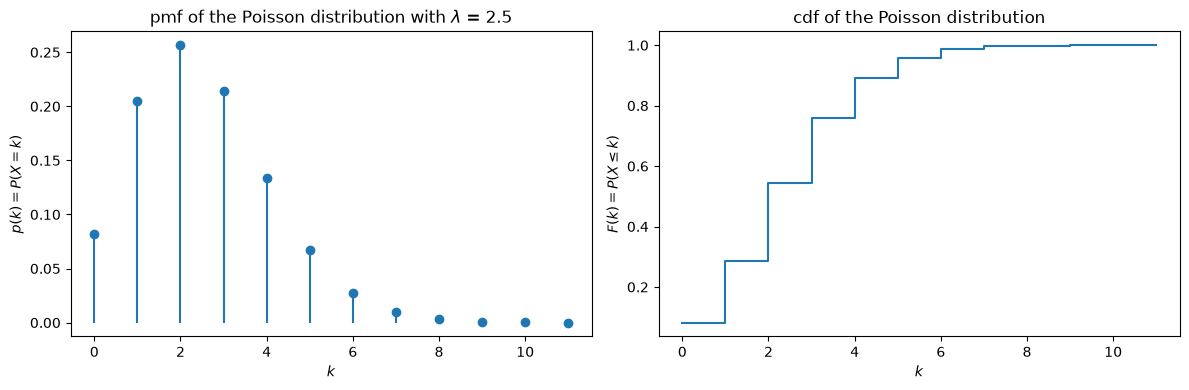

In [10]:
lam = 2.5
X = st.poisson(lam)
print("E(X) =", X.mean(), " V(X) =", X.var(), " (both equal to lambda)")
print("P(X > 2) =", X.sf(2), " by hand:", 1 - np.exp(-lam) * (1 + lam + lam**2 / 2))

plotXdiscrete(np.arange(0, 12), X, "Poisson distribution", (f"$\\lambda$ = {lam}",))


## For completeness: the geometric distribution

* Parameter $p \in (0,1]$, notation $\operatorname{Geom}(p)$
* pmf $p(k) = (1-p)^{k-1}p$ for $k \in \{1,2,3,\dots\}$
* Expected value $\dfrac{1}{p}$
* Variance $\dfrac{1-p}{p^2}$
* Example applications:
  * How many times do I have to throw a die until the first six comes up? ($p = \frac16$, on average $6$ throws)
  * How many connection attempts does it take until the first success?
* In `scipy.stats`: `st.geom(p)`

We repeat a Bernoulli experiment until the first success and count
the trials. For the first $k-1$ trials to fail and the $k$-th to succeed has probability
$(1-p)^{k-1}p$ – hence the pmf.

The geometric distribution is *memoryless*: if you have already thrown the die ten times in vain, the
probability of needing another $k$ throws is the same as it was at the start. The die does not
remember. It is thus the discrete counterpart of the exponential distribution, the only memoryless
distribution in the continuous case.

```{admonition} Caution
:class: warning
There are two conventions in common use: the number of **trials up to the first success** (then $k \geq 1$,
expected value $\frac1p$) and the number of **failures before it** (then $k \geq 0$, expected value
$\frac{1-p}{p}$). We use the first, and so does `scipy.stats.geom`.
```


E(X) = 6.0  expected: 6.0
V(X) = 30.000000000000007  expected: 30.000000000000004


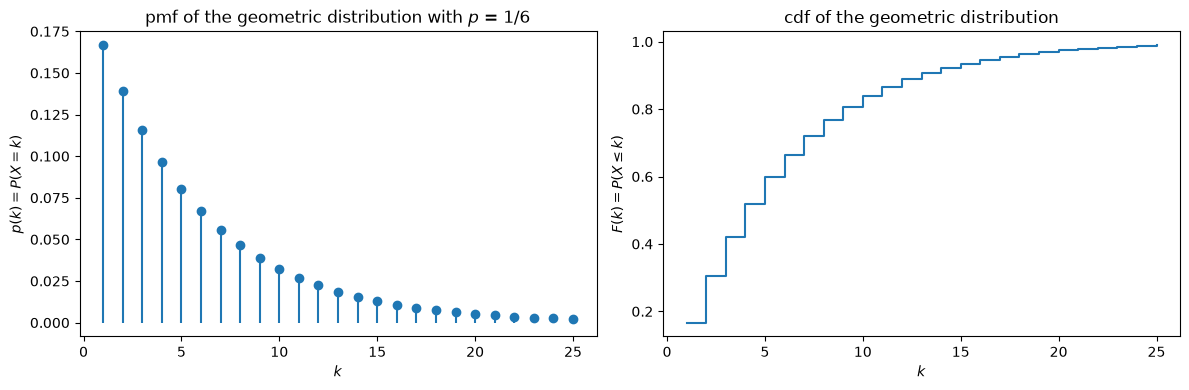

In [11]:
p = 1 / 6
X = st.geom(p)
print("E(X) =", X.mean(), " expected:", 1 / p)
print("V(X) =", X.var(),  " expected:", (1 - p) / p**2)

plotXdiscrete(np.arange(1, 26), X, "geometric distribution", (f"$p$ = 1/6",))


## Looking back

All the distributions in this chapter hang together:

* The **categorical distribution** is the most general distribution on a finite set; its
  parameter space is the simplex $\Delta_n$.
* The **discrete uniform distribution** is the centre of that simplex and has maximal entropy.
* The **Bernoulli distribution** is the case $n=2$.
* The **binomial distribution** counts the successes in $n$ independent Bernoulli trials with the same $p$,
  the **Poisson binomial distribution** allows different $p_i$.
* The **Poisson distribution** is their limiting case for many trials, each of them very unlikely.
* The **geometric distribution** turns the question around: not how many successes in a fixed number of trials,
  but how many trials up to the first success.

Next we leave countable sets of outcomes behind. Look at the binomial distribution not
for small $p$ but for large $n$, and the passage to the limit leads not to the Poisson distribution
but to the **normal distribution** – that is the de Moivre–Laplace theorem, and the chapter
[The normal distribution](normal-distribution.ipynb) opens with it.
